In [ ]:
# 문제 및 과제 선정
# 제시된 데이터 : 공부 시간과 최종 시험 성적
# 모델
# 독립변수 : 공부 시간
# 종속변수 : 최종 시험 성적
# 가설: 공부시간이 비례할 수록 최종 시험 성적도 비례할 것이다.
'''
머신러닝 / 딥러닝 모델링 과정
1. 라이브러리 다운 및 데이터 세트 다운로드
- 필요 시 개발환경 내 폴더를 구성하거나 파일의 접근 권한을 구성하는 등의 설정도 할 수 있다.
2. 데이터 세트 선언 및 데이터 전처리
3. 모델 선언
4. 모델 학습
5. 모델 평가 (중요)
'''

'''
모델을 선언 및 설계할 때 사용되는 모듈이며, 다음과 같은 기능을 한다.
1. forward 매서드 지원
2. nn.Linear, nn.CrossEntropyLoss, nn.Sequential 등 신경망 구성에 지원하는 모듈 제공
3. nn.Module 을 모델이 상속받음으로써 순전파와 역전파가 자동적으로 실행
'''

'''
Dataset : 데이터세트 클래스. __getitem__ 을 어떻게 설정하느냐에 따라서 입력변수와 출력변수가 결정된다.
DataLoader : 학습에 필요한 배치 설정, 셔플 설정, 데이터 분리 등의 기능 제공
'''

In [ ]:
df = pd.read_csv("student_performance_dataset.csv")
df.head()
# 단순한 선형회귀 x
# 여러 신경망과 활성화를 다층퍼셉트론
# 출력값에는 활성화 x

'''
nn.Sequential(nn.Linear(4, 8),
              nn.ReLU(),
              nn.Linear(8, 4)
              nn.ReLU(),
              nn.Linear(4, 1))
'''

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/harshadapatil31/student-performance-and-study-habits-dataset
License(s): CC0-1.0
100% 14.7k/14.7k [00:00<00:00, 35.5MB/s]

Data size: (1000, 2)
epoch: 10, loss: 277.36
epoch: 20, loss: 99.69
epoch: 30, loss: 51.11
epoch: 40, loss: 42.56
epoch: 50, loss: 39.04
epoch: 60, loss: 35.06
epoch: 70, loss: 30.65
epoch: 80, loss: 26.17
epoch: 90, loss: 21.98
epoch: 100, loss: 18.29
epoch: 110, loss: 15.18
epoch: 120, loss: 12.73
epoch: 130, loss: 10.85
epoch: 140, loss: 9.49
epoch: 150, loss: 8.57
epoch: 160, loss: 7.99
epoch: 170, loss: 7.64
epoch: 180, loss: 7.44
epoch: 190, loss: 7.34
epoch: 200, loss: 7.28
Training Complete
평가점수: 7.36


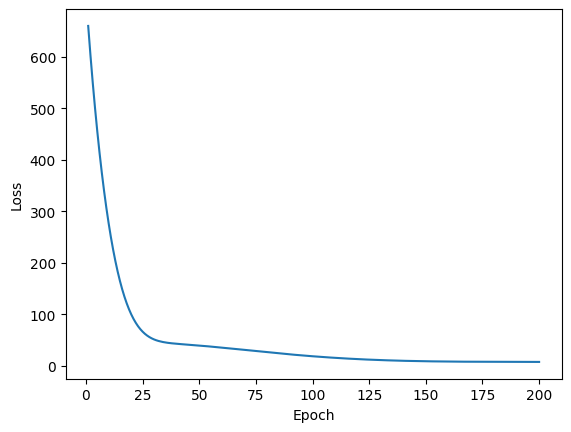

In [ ]:
# 전체 코드
import torch
from torch import optim
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

!pip install -q kaggle
files.upload()
!kaggle datasets download harshadapatil31/student-performance-and-study-habits-dataset
!unzip -q student-performance-and-study-habits-dataset.zip
!mkdir /content/models

df = pd.read_csv("student_performance_dataset.csv")
df = df[['study_time_hours', 'final_exam_score']]
df = df.dropna(axis = 0)
print("Data size:", df.shape)

# model definition
class MyDataset1(Dataset):
  def __init__(self, df):
    self.df = df
    self.x = self.df.iloc[:,0].values
    self.y = self.df.iloc[:,1].values
    self.length = len(self.df)

  def __getitem__(self, index):
    x = torch.FloatTensor([self.x[index]])
    y = torch.FloatTensor([self.y[index]])
    return x, y

  def __len__(self):
    return self.length

class MyModel1(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer = nn.Linear(1,1)

  def forward(self, x):
    x = self.layer(x)
    return x

# Trainer
device = 'cuda' if torch.cuda.is_available() else 'cpu'
dataset = MyDataset1(df)
train_size = 800
eval_size = 200
batch_size = 10
train_dataset, eval_dataset = random_split(dataset, [train_size, eval_size])
train_dataloader = DataLoader(train_dataset, batch_size = batch_size,
                                 shuffle = True,
                                 drop_last = True)
eval_dataloader = DataLoader(eval_dataset, batch_size = batch_size,
                             shuffle = True,
                             drop_last = True)

learning_rate = 0.01
epoch = 200

model = MyModel1().to(device)
criterion = nn.MSELoss().to(device)
optimizer = optim.Adam(model.parameters(), lr = learning_rate)


epoch_memory = [x+1 for x in range(200)]
loss_memory = []
checkpoint = 0

for epoch in range(epoch):
  cost = torch.FloatTensor([0.0])
  for x, y in train_dataloader:
    x = x.to(device)
    y = y.to(device)
    output = model(x)

    loss = criterion(output, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    cost += loss

  loss_memory.append(round(cost.item() / len(train_dataset), 2))
  checkpoint += 1

  if (epoch+1) % 10 == 0:
      print(f"epoch: {epoch+1}, loss: {(cost.item() / len(train_dataset)):.2f}")

  if (epoch+1) % 100 == 0:
    torch.save({"model" : "MyModel",
                "epoch" : epoch,
              "model_state_dict":model.state_dict(),
              "optimizer_state_dict":optimizer.state_dict(),
              "cost":cost,
              "description":f"MyModel Checkpoint {checkpoint}"
              }, f"models/checkpoint-{checkpoint}.pt")

plt.plot(epoch_memory, loss_memory)
plt.xlabel('Epoch')
plt.ylabel('Loss')

torch.save(model, "models/model.pt")
torch.save(model.state_dict(), "models/model_state_dict.pt")
print('Training Complete')

# evaluation
model = torch.load('models/model.pt', map_location = device, weights_only = False)
model.eval()

with torch.no_grad():
  cost = torch.FloatTensor([0.0])
  for x, y in eval_dataloader:
    x = x.to(device)
    y = y.to(device)
    output = model(x)
    loss = criterion(output, y)
    cost += loss.item()


model = torch.load('models/model.pt', map_location = device, weights_only = False)
cost = round(cost.item() / len(eval_dataset), 2)
print('평가점수:', cost)

# inference
def model_infer(x):
  model = torch.load('models/model.pt', map_location = device, weights_only = False)
  model.eval()

  output = round(model(torch.FloatTensor([x]).to(device)).item())
  if output >= 100 :
    output = 100

  return output

In [ ]:
model.eval()
print(model.parameters())
a = list(model.parameters())
print(a)

'''
model.parameters()는 모델의 모든 파라미터를 한 번에 메모리에 로드하지 않고,
순차적으로 꺼내 쓸 수 있도록 만드는 제너레이터(Generator) 객체를 반환합니다.
'''

<generator object Module.parameters at 0x7e4232ff8900>
[Parameter containing:
tensor([[4.4005]], requires_grad=True), Parameter containing:
tensor([67.6096], requires_grad=True)]


In [ ]:
A = torch.FloatTensor(
    [
        [1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]
    ]
    )
A.sum()

tensor(45.)

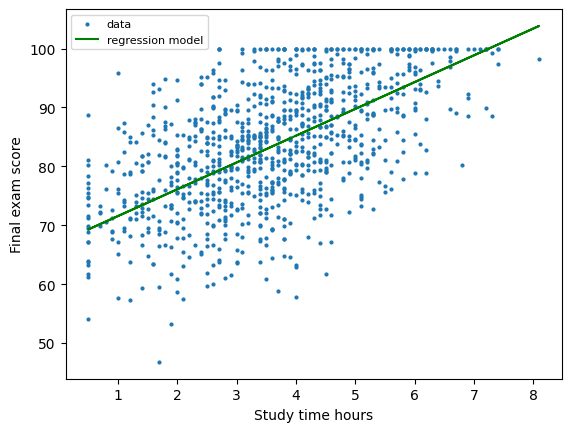

In [ ]:
# 전체 코드 - visualization
dataframe = pd.read_csv("student_performance_dataset.csv")
x = dataframe['study_time_hours']
y1 = dataframe['final_exam_score']


x_model = torch.FloatTensor(x).unsqueeze(0) #[1,2,3,] > [[1,2,3,4]] > [[1],[2],[3],[4]]
x_model = torch.transpose(x_model, 0, -1)
y2 = model(x_model)
y2 = y2.detach().numpy()


plt.scatter(x, y1, s = 4, label = 'data')
plt.plot(x, y2, color = 'g', label = 'regression model')
plt.xlabel('Study time hours')
plt.ylabel('Final exam score')
plt.legend(loc = 'best', fontsize = 8)

In [ ]:
import torch
from torch import optim
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

!pip install -q kaggle
files.upload()
!kaggle datasets download harshadapatil31/student-performance-and-study-habits-dataset
!unzip -q student-performance-and-study-habits-dataset.zip
!mkdir /content/models

ERROR: Operation cancelled by user


Dataset URL: https://www.kaggle.com/datasets/harshadapatil31/student-performance-and-study-habits-dataset
License(s): CC0-1.0
student-performance-and-study-habits-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace student_performance_dataset.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: mkdir: cannot create directory ‘/content/models’: File exists
Data size: (1000, 2)


In [ ]:
# 코드 분석
# -------------------------------------------------------------------------------------------------
# 코드를 분석하기 앞서
'''
머신러닝 연구 단계
1. 문제 정의 및 가설 설정
2. 데이터 수집 및 전처리
3. 베이스라인 구축 및 모델 설계
4. 모델 학습 및 하이퍼파라미터 튜닝
5. 성능 평가
6. 결과 해석

예시
1. 문제 정의 및 가설 설정: 학생의 공부 시간과 시험 성적 간의 관계 탐색 > 선형적으로 비레한다는 가설 설정
2. 데이터 수집: 머신러닝 데이터 플랫폼인 Kaggle로부터 student performance dataset 사용
3. 베이스라인 구축 및 모델 설계: 해당 코드 (설계)
4. 모델 학습 및 하이퍼파라미터 튜닝: 해당 코드 (학습)
5. 성능 평가: 해당 코드 (평가)
6. 결과 해석 해당 코드 (시각화)

구글 코랩이란?
웹 브라우저 / 클라우드 컴퓨팅 기반 파이썬 개발 환경
- 로컬 환경에 상관없이 통일된 환경에서 개발할 수 있음
- 구글에서 제공해주는 고성능 CPU와 GPU/TPU를 사용할 수 있음
- 로컬 환경에 상관없이 리눅스 기반 가상환경에서 작동함. 런타임이 끊기면 코드를 실행하고 다운로드했던 기록이 모두 초기화됨
- 루트 디렉토리 안에 content/ (기본 작업 공간)과 다른 디렉토리로 구성되어 있으며,
  파일을 임포트하거나 데이터세트를 사용하려면 루트 디렉토리 안에 파일과 데이터 세트가 정의되어 있어야 함.

'''
# -------------------------------------------------------------------------------------------------
# 코드의 구조
'''
a. 모델 설계 (MyDataset1, MyModel1)
b. 하이퍼파라미터 설정
    device : 학습 시 cpu를 사용할지 gpu를 사용할지 선택할 수 있도록 하는 변수
    dataset : 학습 데이터세트 + 평가 데이터세트
    batch_size : 모델 학습 시 한 번의 연산 당 모델의 입력으로 제공할 데이터의 수
    train_size, eval_size : 학습 데이터와 평가 데이터의 수
    train_dataset, eval_dataset : 학습 데이터 세트, 평가 데이터 세
    train_dataloader, eval_dataloader : 데이터세트로부터 모델이 데이터를 학습할 수 있는 형태로 공급해주는 클래스 (학습데이터1, 평가데이터1)
    learning_rate : 학습률, 오차역전파 공식 내 변수
    epoch : 전체 데이터 세트를 한 번 모두 훑어보고 학습을 완료한 단위 (ex. 에포크가 200이라면 데이터세트 전체를 200번 훑은 것)
    model : 모델 (신경망 + 활성화함수 + 학습 파라미터)
    criterion : 손실 함수 (MSE)
    optimizer : 최적화 알고리즘

c. 모델 학습 (for epoch in range~)
d. 모델 평가
e. 결과 분석 (시각화)
'''
# -------------------------------------------------------------------------------------------------
# 라이브러리 로드
'''
1. pytorch : 머신러닝/딥러닝 프레임워크
>> 동적계산그래프, GPU 가속, 연구 및 서비스 환경 지원으로 장점을 지니고 있는 라이브러리이다.
>> 동적계산그래프 : 실행 시점에 신경망의 계산 그래프를 생성하는 방식 ("밑바닥부터시작하는딥러닝" 참고)
2. numpy : 다차원 수치 배열을 고속으로 처리하기 위한 라이브러리. 파이토치, 판다스와 높은 호환성을 지니고 있다.
3. pandas : 넘파이 기반 데이터 분석 및 전처리 라이브러리
4. matplotlib : 데이터 시각화 라이브러리
5. google.colab : 캐글로부터 연동해서 구글 코랩 내 작업 환경으로 데이터를 다운받기 위해 사용하는 라이브러리
'''

import torch
from torch import optim
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
# -------------------------------------------------------------------------------------------------
# 가상 환경에 필요한 라이브러리 다운로드
# # torch, numpy pandas 등 위의 라이브러리 등은 import 코드만 사용해도 알아서 다운로드 해주거나 이미 다운로드가 되어 있음.
'''
Kaggle로부터 데이터 세트를 받는 가장 간단한 방법은
로컬 환경에 zip 형태로 다운로드를 받고 압축을 풀어서 코랩 가상 폴더 내 원하는 위치에 드래그해서 끌어놓으면 되지만
용량 + 귀찮음 이슈로 다음과 같은 방법을 사용하기도 한다.

file.upload() 코드를 사용하여 content 디렉토리에 자신의 API키와 정보가 담겨 있는 kaggle.json 폴더를 업로드한다.
이후 !kaggle datasets download ~ 를 입력하여 원하는 데이터 세트를 다운 받는다.
다운 받은 파일의 압축을 푼다.

!mkdir /content/models 은 학습한 모델을 저장하기 위한 폴더로서 학습 후 가독성을 위해 따로 추가해준다 (선택적임)
'''
!pip install -q kaggle
files.upload()
!kaggle datasets download harshadapatil31/student-performance-and-study-habits-dataset
!unzip -q student-performance-and-study-habits-dataset.zip
!mkdir /content/models
# -------------------------------------------------------------------------------------------------
# 데이터 전처리
# 데이터를 읽어내어 pandas에서 지원하는 DataFrame 클래스로 저장
df = pd.read_csv("student_performance_dataset.csv")
# 전체 데이터에서 사용할 변수를 분리하여 DataFrame 클래스로 저장
df = df[['study_time_hours', 'final_exam_score']]
# 결측값 (열이나 행에서 빠진 데이터) 제거
df = df.dropna(axis = 0)
# 전처리 이후 데이터의 구조 확인
print("Data size:", df.shape)

# 데이터는 DataFrame으로 존재
# model definition
# 모델을 설계할 때는 Dataset와 Model 두 가지 클래스를 반드시 설계해야 한다.
# -------------------------------------------------------------------------------------------------
# 데이터세트 클래스
'''
- 모델에 입력할 수 있는 형태의 단일 샘플 단위로 변환해준다.
- 독립변수(입력)와 종속변수(출력) 지정해준다.
- 내가 설계한 커스텀 데이터세트 클래스가 제 기능을 하려면
__getitem__과 __len__ 함수가 아래처럼 올바르게 정의되어야 한다.
'''
class MyDataset1(Dataset):
  def __init__(self, df):
    self.df = df
    self.x = self.df.iloc[:,0].values # numpy.ndarray
    self.y = self.df.iloc[:,1].values # numpy.ndarray
    '''
    만약 다중 선형회귀라면 self.x 부분을 바꿔주어야 한다.
    ex. 0열 1열 2열에 각각 x1, x2, y를 전처리 해놓고 self.x = self.df.iloc[:,0:2].values
        그렇게되면 결과인 x의 ndarray는 [[x1, x2],[x1, x2],[x1, x2],[x1, x2]...]와 같은 배열이 된다
    '''
    self.length = len(self.df)

  def __getitem__(self, index):
    x = torch.FloatTensor([self.x[index]]) # 참고: ndarray는 인덱싱이 된다. 값이 호출
                                           # 호출된 값을 텐서화하는 코드이다.
    y = torch.FloatTensor([self.y[index]]) # 즉, 데이터 세트 클래스에서 인덱싱으로 호출된 값은 (텐서, 텐서) 여야 한다.
    return x, y

  def __len__(self):
    return self.length
# -------------------------------------------------------------------------------------------------
# 모델 클래스
# 모델 클래스에서 신경망과 활성화 함수를 정의한다.
'''
nn.Module이란?
모델을 구성하는 레이어와 신경망의 최상위 기본 클래스. 즉 모델을 정의할 때는 꼭 nn.Module을 상속받아야 한다.

nn.Module의 기능
1. 가중치 추적 및 관리
2. device(cpu/gpu) 메모리로 데이터 타입 운반
3. 학습 및 평가 모드 전환
4. 파라미터/모델 저장 및 불러오기

nn.Module의 규칙
super().__init__()으로 초기화 메서드 반드시 호출
forward 함수 정의
forwar 함수의 기능 ( == __call__)
ex. mymodel = model()
    mymodel(1)
    >> 추론 결과 반환
'''
class MyModel1(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer = nn.Linear(1,1)
    # nn.Linear(1, 10)
    # nn.Linear(10, 1)
  '''
    nn.Sequential(
        nn.Linear(1,10),
        nn.Linear(10,1),
        nn.ReLU()
        )

    nn.Sequential(
        nn.Linear(4, 6),
        nn.ReLU()
        nn.Linear(6, 6),
        nn.ReLU()
        nn.Linear(6,3),
        nn.ReLU()
        nn.Linear(3,2),
        nn.Softmax()
        )

  '''
    # nn.Linear(input dimension, output dimension)
  def forward(self, x):
    x = self.layer(x)
    return x
# -------------------------------------------------------------------------------------------------
# model = Mymodel1()
# model(0) > forward 연산

Saving kaggle.json to kaggle (1).json
Dataset URL: https://www.kaggle.com/datasets/harshadapatil31/student-performance-and-study-habits-dataset
License(s): CC0-1.0
student-performance-and-study-habits-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace student_performance_dataset.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
mkdir: cannot create directory ‘/content/models’: File exists
Data size: (1000, 2)


epoch: 10, loss: 298.92
epoch: 20, loss: 106.92
epoch: 30, loss: 51.70
epoch: 40, loss: 41.71
epoch: 50, loss: 38.31
epoch: 60, loss: 34.56
epoch: 70, loss: 30.34
epoch: 80, loss: 26.03
epoch: 90, loss: 21.96
epoch: 100, loss: 18.35
epoch: 110, loss: 15.30
epoch: 120, loss: 12.88
epoch: 130, loss: 11.03
epoch: 140, loss: 9.66
epoch: 150, loss: 8.74
epoch: 160, loss: 8.13
epoch: 170, loss: 7.77
epoch: 180, loss: 7.56
epoch: 190, loss: 7.44
epoch: 200, loss: 7.38
Training Complete
평가점수: 7.14


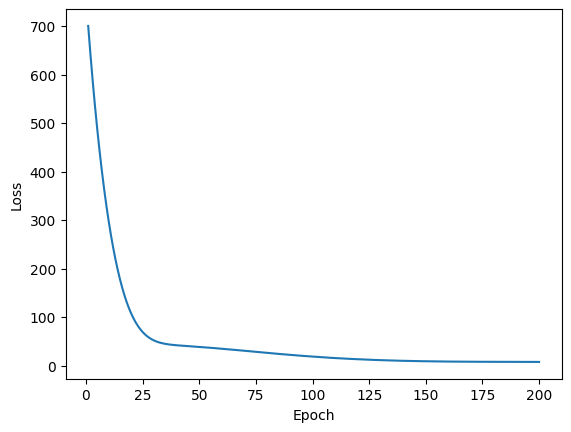

In [ ]:
# Trainer
# 하이퍼파라미터 설정
device = 'cuda' if torch.cuda.is_available() else 'cpu'
dataset = MyDataset1(df) # 이전에 정의한 df와 데이터세트 클래스
train_size = 800
eval_size = 200
batch_size = 10
train_dataset, eval_dataset = random_split(dataset, [train_size, eval_size])
train_dataloader = DataLoader(train_dataset, batch_size = batch_size,
                                 shuffle = True, # 모델에 데이터를 보낼 때 섞어서 보낼 건지
                                 drop_last = True) # 배치 단위로 데이터를 쪼개고 나머지는 버릴 건지
eval_dataloader = DataLoader(eval_dataset, batch_size = batch_size,
                             shuffle = True,
                             drop_last = True)

learning_rate = 0.01  # 얼마나 많은 보폭으로 이동할거냐
epoch = 200

# 모델과 손실 함수는 막대한 양의 가중치를 직접 계산하기 때문에 gpu로 반드시 올려야 한다.
model = MyModel1().to(device)
criterion = nn.MSELoss().to(device)
optimizer = optim.Adam(model.parameters(), lr = learning_rate)
# ------------------------------------------------------------------------------
epoch_memory = [x+1 for x in range(200)] # 시각화 할 x축
loss_memory = [] # 시각화 할 y축
checkpoint = 0 # 체크포인트. 중간의 모델 학습을 끊고 재개해야 할 때 체크포인트를 저장해두면 편리하다.

# 메인 학습 루프
for epoch in range(epoch): # 에포크 단위
  cost = torch.FloatTensor([0.0]) # 누적 손실
  for x, y in train_dataloader:# 배치 단위
    x = x.to(device) # 꼭 gpu에 태워야 함
    y = y.to(device) # 꼭 gpu에 태워야 함
    output = model(x) # 출력값
    loss = criterion(output, y) # 출력과 정답 사이의 손실

    optimizer.zero_grad() # 이전 텐서에 누적되어 있던 기울기값을 모두 0으로 초기화
    # 이걸 안 하면 기울기가 누적됨 전 단계에서의 기울기값 + 현 단계 기울기값 .....
    loss.backward() # 역전파 연산
    optimizer.step() # 가중치 업데이트

    cost += loss # 누적 손실 추가

  loss_memory.append(round(cost.item() / len(train_dataset), 2)) # 시각화 할 y축
  checkpoint += 1

  if (epoch+1) % 10 == 0: # 학습 로그 (에포크 10단위 마다 평균 손실 보고)
      print(f"epoch: {epoch+1}, loss: {(cost.item() / len(train_dataset)):.2f}")

  if (epoch+1) % 100 == 0: # 에포크 100단위마다 모델 저장.
                           # 이때는 파라미터 뿐만 아니라 옵티마이저 설정, 손실까지 모두 저장해야함.
    torch.save({"model" : "MyModel",
                "epoch" : epoch,
              "model_state_dict":model.state_dict(),
              "optimizer_state_dict":optimizer.state_dict(),
              "cost":cost,
              "description":f"MyModel Checkpoint {checkpoint}"
              }, f"models/checkpoint-{checkpoint}.pt")

plt.plot(epoch_memory, loss_memory)
plt.xlabel('Epoch')
plt.ylabel('Loss')

# 학습 종료 후 저장
# 모델의 클래스 구조까지 저장
torch.save(model, "models/model.pt")
# 가중치만 저장 즉, state_dict를 로드시에는 사전에 해당 가중치에 맞는 모델이 내 코드에 정의되어 있어야 함
torch.save(model.state_dict(), "models/model_state_dict.pt")
print('Training Complete')
# -------------------------------------------------------------------------------------------------
# evaluation
# 모델 로드
model = torch.load('models/model.pt', map_location = device, weights_only = False)
model.eval() # 평가 모드 또는 출력만 필요할 시에 사용. 해당 코드에서는 큰 차이가 없으나 드롭아웃이나 배치 정규화 레이어에서는 초기화 방식에 차이가 발생한다.
'''
1. 드롭아웃 레이어 (nn.Dropout)
학습 모드 (model.train()): 과적합(Overfitting)을 방지하기 위해 지정된 비율(예: 50%)만큼의 노드를
무작위로 비활성화(0으로 만듦)시킵니다.

평가 모드 (model.eval()): 모든 노드를 활성화하여 100%의 노드로 예측/추론 연산을 수행합니다.
(드롭아웃 연산이 비활성화됨)

2. 배치 정규화 레이어 (nn.BatchNorm1d, nn.BatchNorm2d 등)
학습 모드 (model.train()): 현재 들어온 미니배치(Mini-batch)의 평균과 분산을 매번 새로 계산하여 정규화하고,
이동 평균(Running Mean/Variance)을 누적 기록합니다.

평가 모드 (model.eval()): 새로운 배치의 통계량을 계산하지 않고,
학습하는 동안 누적해 둔 전체 데이터셋의 이동 평균과 이동 분산 값을 고정하여 사용합니다.
'''

# 역전파를 수행하지 않으므로 미분 설정도 꺼야 함
with torch.no_grad():
  cost = torch.FloatTensor([0.0])
  for x, y in eval_dataloader:
    x = x.to(device)
    y = y.to(device)
    output = model(x)
    loss = criterion(output, y)
    cost += loss.item()

model = torch.load('models/model.pt', map_location = device, weights_only = False)
cost = round(cost.item() / len(eval_dataset), 2)
print('평가점수:', cost)

# inference
# 추론 모드 : 모델을 실사용할 때이다. 편의 상 함수 모듈을 이용하여 정의한다.
def model_infer(x):
  model = torch.load('models/model.pt', map_location = device, weights_only = False)
  model.eval()

  output = round(model(torch.FloatTensor([x]).to(device)).item())
  if output >= 100 :
    output = 100

  return output

In [ ]:
model_infer(9)
model_infer(1)
model_infer(0)
model_infer(7)

99